# Bike Sharing Project

Your task is to **predict how many bikes are rented in an hour** in the Capital Bikeshare system of Washington, D.C., and to find out how far **ensemble methods** improve on a single decision tree and on a linear model. In the project you combine everything you learned this week, from decision trees to boosting, voting and stacking, into one complete analysis.

The task below follows the steps of a machine learning project, in a single pass:

![The project in one pass, from top to bottom: 1. goal and metric, 2. get the data, 3. a train-test split into training data and locked test data. Steps 4 and 5 (explore, baselines) use only the training data. Steps 6 and 7 form the model selection loop: feature engineering, set hyperparameters, train model(s) and calculate the cross-validation score, then repeat. In step 8, the test data is unlocked, the models are scored on the test set and the hours with the largest errors are examined](assets/bike_sharing_project_workflow.png)

# The Business Problem

The operations team of Capital Bikeshare plans its work hour by hour: how many bikes have to be available, how many trucks move bikes between stations, and how many staff are on duty. To plan, they need to know **how many bikes are rented in an hour under given conditions**: the time of day, the type of day, the season and the weather. A Tuesday at 17:00 in summer needs very different planning from a rainy Sunday morning in January.

Your model answers this question: given the conditions of an hour, it predicts its rentals. The more accurate it is, the better the team can plan, so you compare several models and choose the best one. At the end, you look at **where the model makes its biggest mistakes**, so that the team knows when they can trust its numbers and when not.

The model describes typical hours under given conditions; it is not used to forecast particular future dates. The hours you hold back as a test set can therefore be drawn **at random** from the whole period. A forecast would be a different problem: there the model has to predict hours that come after everything it was trained on, so the test set would have to be the most recent hours.

# Data Description

The data covers **two years, October 2024 to September 2026**, and ships with this repository as one table, `data/bike_sharing.csv`, with **one row per hour**. It combines three sources:

- the number of bikes rented in each hour, from the trip records that [Capital Bikeshare](https://capitalbikeshare.com/system-data) publishes. Every trip is counted in the hour in which it started;
- the weather in central Washington, D.C. in each hour, from the [Open-Meteo](https://open-meteo.com/) historical weather archive;
- the public holidays of Washington, D.C.

| Column | Source | Description |
| :-- | :-- | :-- |
| `datetime` | | start of the hour, local time in Washington, D.C. |
| `casual` | rentals | rentals by casual riders, who pay per ride or per day |
| `member` | rentals | rentals by members with an annual or monthly membership |
| `rentals` | rentals | total number of rentals in the hour, **the prediction target** |
| `temperature` | weather | air temperature in °C |
| `feels_like` | weather | apparent ("feels like") temperature in °C, which accounts for wind and humidity |
| `humidity` | weather | relative humidity in % |
| `precipitation` | weather | rain and snow in the hour, in mm of water |
| `snowfall` | weather | snowfall in the hour, in cm |
| `wind_speed` | weather | wind speed in km/h |
| `cloud_cover` | weather | share of the sky covered by clouds, in % |
| `weather_code` | weather | type of weather as a [WMO code](https://open-meteo.com/en/docs/historical-weather-api): 0 clear, 1 to 3 partly cloudy to overcast, 51 to 55 drizzle, 61 to 65 rain (light to heavy), 71 to 75 snow (light to heavy) |
| `holiday` | holidays | name of the public holiday on that day, empty on all other days |

Rentals data © Capital Bikeshare, used under the [Capital Bikeshare Data License Agreement](https://capitalbikeshare.com/data-license-agreement). Weather data by [Open-Meteo.com](https://open-meteo.com/), licensed [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/).

## Task

1. **Set your goal.** Decide which metric you use to judge the model, and explain why. Think about what the operations team needs to read from it.
2. **Get the data.** Load `data/bike_sharing.csv`, and take a first look at its size and columns. Turn `datetime` into a date type, so that you can extract the hour, the weekday or the month from it later.
3. **Split the data into a training and a test set.** Use `train_test_split` once. Choose the size of the test set with `test_size`, and fix the `random_state`, so that you get the same split every time you run the notebook. Keep the features and the target together: the result should be two DataFrames, `df_train` and `df_test`, that both still contain the `rentals` column. In step 7, cross-validation on the training set takes the place of a validation set. Do not look at `df_test` until step 8.
4. **Explore the training set.** How do the rentals change over the day, and is that pattern the same on working days, weekends and holidays? How do the weather columns relate to the rentals? Which columns contain the same information? Check every column carefully: **would you know its value for an hour without having counted that hour's rentals?**

> [!IMPORTANT]
> **Keep a record of every change you make to the training data by hand.** In step 8 you apply exactly the same changes to the test set. This covers, for example, new columns such as the hour of the day or a flag for working days that you extract from `datetime` and `holiday`, and every column you drop. Put these changes into a function, so that you can call the same function on the test set. Transformations inside your `Pipeline` (scaling, encoding) are applied to the test set automatically, with the values learned on the training data.

5. **Separate the features from the target, and build two baselines.** Split `df_train` into `X_train` and `y_train`; the test set stays untouched until step 8. Then build two simple models that your models have to beat:
    - a **mean baseline** with [`DummyRegressor`](https://scikit-learn.org/stable/modules/generated/sklearn.dummy.DummyRegressor.html), which predicts the mean number of rentals of the training set for every hour, and
    - a **rule-based baseline** built from what you found in step 4, that a person could calculate by hand. Learn the values of the rule on the training data.
6. **Train a linear model and a single decision tree.** Train a regularised linear model, for example `Ridge`, in a `Pipeline` with the preprocessing it needs, and a `DecisionTreeRegressor`. Compare them with cross-validation: which one handles the pattern over the day better, and why? Does the tree need the same preprocessing as the linear model?
7. **Build, tune and compare ensembles with cross-validation.** Train at least:
    - a **random forest** (`RandomForestRegressor`),
    - a **gradient boosting model**, for example `XGBRegressor` or `CatBoostRegressor`: for a number, use the regressor and a regression metric. CatBoost can treat columns as categories itself (`cat_features`): find out whether that helps here,
    - and a **combination of models** with `VotingRegressor` or `StackingRegressor`.

    Tune at least one of the models with `RandomizedSearchCV` (or `GridSearchCV`), and choose the best model by its cross-validated score. **Save every model in its own variable** (and the values of your rule), so that you can evaluate all of them in the last step.
8. **Prepare the test set and evaluate all models at the very end.** First apply to `df_test` the changes you made by hand to the training data, and split it into `X_test` and `y_test`. Then calculate the **training and the test scores of every model** with your chosen metric, including both baselines, and collect them in **one table**: one row per model, with columns for the training and the test scores. Compare the models: which ones beat the baselines, how much did each step from the linear model to the ensembles gain, and how large is the difference between training and test scores?

    Finally, find out **where your best model makes its biggest mistakes**, so that the operations team knows when to trust it:
    1. **Calculate the residuals** of the test hours: actual rentals minus predicted rentals. A large positive residual means the model predicted far too few rentals, a large negative one far too many. Use only the test hours: the model has seen the training hours, so its errors there are too small to tell you anything.
    2. **Plot the residuals**: a scatter plot of the residuals against the predicted rentals, with a line at 0, and the size of the residuals by hour of the day (for example a box plot). Where does the model make its largest errors, and do the errors grow with the number of rentals?
    3. **Compare predicted and actual rentals over the day**: plot the mean actual and the mean predicted rentals for each hour of the day, separately for working days and weekends. Does the model reproduce the daily pattern you found in step 4? At which hours does it predict too many or too few rentals on average?
    4. **List the hours with the biggest mistakes**: the 10 hours with the largest positive and the 10 with the largest negative residuals, with their date, time and weather.

> [!TIP]
> If you use `CatBoostRegressor` with `cat_features` inside `cross_val_score` or a search, pass `cat_features` to `.fit()` instead of the constructor (for example `cross_val_score(..., params={"cat_features": [...]})`): set in the constructor, it breaks the copying of the model that cross-validation does.

In [25]:
# Import the libraries you need for this project
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import randint, uniform, loguniform

from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, VotingRegressor, StackingRegressor
from sklearn.dummy import DummyRegressor
from sklearn.metrics import root_mean_squared_error, mean_absolute_error, r2_score
from xgboost import XGBRegressor
from catboost import CatBoostRegressor

from sklearn.linear_model import LinearRegression, ElasticNet

from sklearn.pipeline import make_pipeline

In [2]:
df = pd.read_csv('data/bike_sharing.csv')
df.head()

,datetime,casual,member,rentals,temperature,feels_like,humidity,precipitation,snowfall,wind_speed,cloud_cover,weather_code,holiday
0,2024-10-01 00:00,47,89,136,18.1,19.5,96,0.2,0.0,8.6,100,51,NaN
1,2024-10-01 01:00,18,30,48,18.2,19.6,96,0.1,0.0,8.9,100,51,NaN
2,2024-10-01 02:00,14,17,31,18.2,19.2,94,0.0,0.0,10.3,100,3,NaN
3,2024-10-01 03:00,6,9,15,17.9,18.6,93,0.0,0.0,11.7,100,3,NaN
4,2024-10-01 04:00,7,20,27,17.6,18.1,93,0.1,0.0,12.4,100,51,NaN


In [3]:
# convert to dates
df['datetime'] = pd.to_datetime(df['datetime'])

# Working day vs weekend
df['day_type'] = df['datetime'].dt.dayofweek.map(
    lambda day: 'weekend' if day >= 5 else 'working_day'
)
# expand holiday table
df['holiday'] = df['holiday'].fillna(df['day_type'])
# Hour of day (0–23)
df['hour'] = df['datetime'].dt.hour

# Remove the original date column, if no longer needed
df = df.drop(columns=['datetime'])

In [4]:
df.head()

#df.to_csv('data/bike_sharing_v2.csv', index=False)

,casual,member,rentals,temperature,feels_like,humidity,precipitation,snowfall,wind_speed,cloud_cover,weather_code,holiday,day_type,hour
0,47,89,136,18.1,19.5,96,0.2,0.0,8.6,100,51,working_day,working_day,0
1,18,30,48,18.2,19.6,96,0.1,0.0,8.9,100,51,working_day,working_day,1
2,14,17,31,18.2,19.2,94,0.0,0.0,10.3,100,3,working_day,working_day,2
3,6,9,15,17.9,18.6,93,0.0,0.0,11.7,100,3,working_day,working_day,3
4,7,20,27,17.6,18.1,93,0.1,0.0,12.4,100,51,working_day,working_day,4


In [5]:
hourly_rental = df.groupby(['hour', 'holiday'])['rentals'].mean().unstack()
hourly_rental_b = hourly_rental[hourly_rental.columns[-2:]]

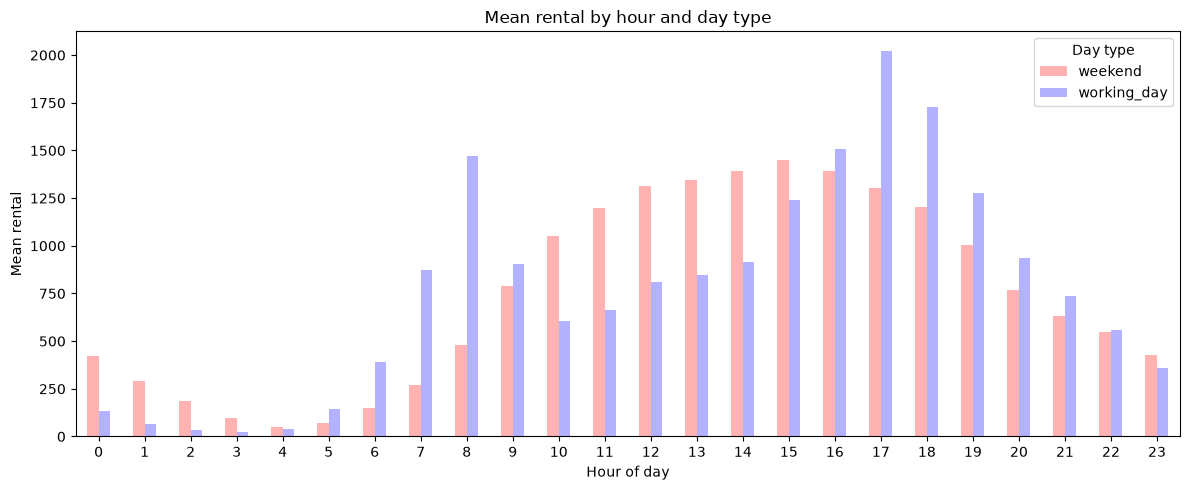

In [6]:
hourly_rental_b.plot(
    kind='bar',
    figsize=(12, 5),
    color=['red', 'blue'],alpha=0.3
)

plt.xlabel('Hour of day')
plt.ylabel('Mean rental')
plt.title('Mean rental by hour and day type')
plt.xticks(range(24), rotation=0)
plt.legend(title='Day type')
plt.tight_layout()
plt.show()

In [21]:
#declaring features and splitting

num_f = ['temperature',	'humidity', 'precipitation',
         'snowfall','wind_speed', 'cloud_cover', 'weather_code', 'hour']
cat_f = ['holiday']

X = df[num_f + cat_f]
y = df['rentals']

RSEED = 42

# Train-test-split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=RSEED
)

def score(prediction):
    """RMSE of a prediction array against the test districts, in units of $100,000."""
    return root_mean_squared_error(y_test, prediction)


print(f"{len(X_train)} training row, {len(X_test)} test row, {X.shape[1]} columns")
print(f"Mean baseline RMSE: {score(np.full(len(y_test), y_train.mean())):.4f}")


13140 training row, 4380 test row, 9 columns
Mean baseline RMSE: 627.9400


In [37]:
X

,temperature,humidity,precipitation,snowfall,wind_speed,cloud_cover,weather_code,hour,holiday
0,18.1,96,0.2,0.0,8.6,100,51,0,working_day
1,18.2,96,0.1,0.0,8.9,100,51,1,working_day
2,18.2,94,0.0,0.0,10.3,100,3,2,working_day
3,17.9,93,0.0,0.0,11.7,100,3,3,working_day
4,17.6,93,0.1,0.0,12.4,100,51,4,working_day
...,...,...,...,...,...,...,...,...,...
17515,22.1,73,0.0,0.0,5.2,96,3,19,working_day
17516,20.8,79,0.0,0.0,6.4,100,3,20,working_day
17517,20.3,81,0.0,0.0,5.6,99,3,21,working_day
17518,19.4,87,0.0,0.0,7.5,99,3,22,working_day


In [ ]:
from sklearn.ensemble import RandomForestRegressor, VotingRegressor, StackingRegressor,Lin
from sklearn.dummy import DummyRegressor
from sklearn.metrics import root_mean_squared_error, mean_absolute_error, r2_score
from xgboost import XGBRegressor
from catboost import CatBoostRegressor

In [97]:
#linReg = poly_pipeline(LinearRegression(tol=0.01))
#linReg_reg_alpha = poly_pipeline(ElasticNet(alpha=0.0004, tol=0.01, max_iter=1000))
#linReg_reg_Ridge = poly_pipeline(Ridge(tol=0.01,alpha=0.0004, max_iter=1000))

def members():
    preprocessor = ColumnTransformer([
        ("num", StandardScaler(), num_f),
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat_f),
    ])

    return [
        ("mGuess", make_pipeline(preprocessor, DummyRegressor(strategy='mean'))),
        ("LinReg", make_pipeline(preprocessor, LinearRegression())),
        ("RanFor", make_pipeline(preprocessor, RandomForestRegressor(n_jobs=150,oob_score=True))),
        ("CaT", make_pipeline(preprocessor, CatBoostRegressor(learning_rate=0.06,verbose=0))),
        ("XGB", make_pipeline(preprocessor, XGBRegressor(n_jobs=-1))),
    ]

NAMES = [name for name, _ in members()]

labels = {}

for name, model in members():
    model.fit(X_train, y_train)
    labels[name] = model.predict(X_test)

scores = pd.DataFrame(
    {
        "RMSE": [root_mean_squared_error(y_test, labels[n]) for n in NAMES],
        "R2": [r2_score(y_test, labels[n]) for n in NAMES],
    },
    index=NAMES,
)

print(scores.to_string(float_format="%.4f"))

           RMSE      R2
mGuess 627.9400 -0.0003
LinReg 449.6673  0.4870
RanFor 193.2860  0.9052
CaT    185.2263  0.9130
XGB    193.2734  0.9052
